# Week 6– Referable Diabetic Retinopathy Classifier 

**Goal.** Train a ResNet-18 (transfer learning) that flags fundus photographs showing *referable* diabetic retinopathy (DR), while avoiding the classic evaluation traps: duplicate images, near-duplicate / same-patient leakage, class imbalance and accuracy as a misleading metric.

**Pipeline at a glance**

| Step | Cell | What happens |
|---|---|---|
| 1 | Config | dataset path, image size, backbone, binary task, target recall |
| 2 | Imports | libraries, seeds, device |
| 3 | Labels | read the csv files, link images, count classes |
| 4 | EDA | image sizes, sample images per DR grade |
| 5 | Pre-processing | resize once, md5 hash, 32 x 32 fingerprint |
| 6 | Exact duplicates | remove identical files |
| 7 | Near-duplicates | group visually near-identical images |
| 8 | Split | stratified + grouped train / val / test |
| 9 | Transforms | augmentation, normalisation, `Dataset` |
| 10 | Class weights | $w_c = N / (K\,n_c)$ |
| 11 | Model | pretrained ResNet-18, freeze the body |
| 12 | Training | 2 epochs head only, 3 epochs fine-tune, select by macro-F1 |
| 13 | Test report | precision, recall, F1, confusion matrix |
| 14 | Threshold | pick the threshold for recall >= 0.95 on validation |
| 15–16 | Grad-CAM | check *where* the network looks |
| 17 | Save | checkpoint + splits |

The last cell of the notebook answers the six Lab 6 revision questions with full working.

## 1. Configuration (the only cell to edit for a new dataset)

All experiment choices live here so that results are reproducible and the rest of the notebook stays untouched.

| Setting | Value | Meaning |
|---|---|---|
| `IMG_SIZE` | 224 | input resolution expected by ImageNet-pretrained ResNets |
| `CACHE_SIZE` | 256 | images are shrunk once to $256 \times 256$ and cached, because the originals are huge |
| `GRAYSCALE` | False | fundus photos are colour; colour carries disease evidence (red haemorrhages, yellow exudates) |
| `BINARY` / `REFERABLE_MIN_GRADE` | True / 2 | task is *referable DR* vs *not referable* |
| `TARGET_RECALL` | 0.95 | the operating point must catch at least 95 % of referable cases |
| `NEAR_DUP_THR` | 0.10 | fingerprint distance below which two images are called near-duplicates |
| `SEED` | 42 | fixed random seed |

**Label rule** (grades: 0 none, 1 mild, 2 moderate, 3 severe, 4 proliferative):

$$
y_i =
\begin{cases}
\text{referable\_DR} & \text{if } g_i \ge 2 \\
\text{non\_referable} & \text{if } g_i \in \{0, 1\}
\end{cases}
$$

The positive class (`referable_DR`) is the one that must not be missed, because a false negative means an untreated eye.

In [5]:
# ============ CHANGE ONLY THIS CELL FOR YOUR OWN DATASET ============
# APTOS 2019 Blindness Detection (diabetic retinopathy, fundus photos).
# Original source: https://www.kaggle.com/c/aptos2019-blindness-detection
# DATA_ROOT may be the competition input or a re-upload (mirror). The code searches it
# recursively for csv files with the columns id_code + diagnosis and for the image files.
DATA_ROOT = '/kaggle/input/datasets/mariaherrerot/aptos2019'
CSV_NAME = None              # None = use every csv under DATA_ROOT that has id_code + diagnosis
                             # (a mirror's own train/valid/test csvs are merged and RE-SPLIT below)
GRAYSCALE = False            # fundus photos are colour: colour carries disease evidence
IMG_SIZE = 224               # network input size
CACHE_SIZE = 256             # images are resized once to this size and cached (the originals are huge)
BACKBONE = 'resnet18'
BINARY = True                # True: referable DR (grade >= REFERABLE_MIN_GRADE) vs not; False: 5 grades
REFERABLE_MIN_GRADE = 2      # 0 none, 1 mild, 2 moderate, 3 severe, 4 proliferative
NORMAL_LABEL = 'non_referable'
POSITIVE = 'referable_DR'    # the class that must not be missed
TARGET_RECALL = 0.95
NEAR_DUP_THR = 0.10          # fingerprint distance below which two images count as near-duplicates
SEED = 42
# ======================================================================

## 2. Imports, random seeds and device

* `torch`, `torchvision`: model, data loading, augmentation.
* `sklearn`: stratified grouped splitting and all metrics.
* `PIL`, `numpy`, `pandas`, `matplotlib`: images, arrays, tables, plots.
* Seeds (`torch.manual_seed`, `np.random.seed` = 42) make the run repeatable.

The printed device is **cpu**, so every training epoch is slow (about 3 to 4 minutes, see the training cell). On a GPU the same epoch would take seconds.

In [6]:
import os
import glob
import time
import copy
import hashlib
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, cohen_kappa_score,
                             roc_auc_score, roc_curve)

torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cpu


## 3. Load labels, link image files, inspect class balance

1. `load_labels` reads every csv containing `id_code` and `diagnosis` (here `train_1.csv`, `valid.csv`, `test.csv`) and **merges** them, because the notebook performs its own, safer split later.
2. Rows with the same `id_code` but conflicting labels would be dropped (none found).
3. `index_images` maps each file stem to its path so every label gets an image.
4. The 5 DR grades are collapsed to the binary label and the class counts are printed.

The imbalance ratio is $\text{IR} = \dfrac{n_{\max}}{n_{\min}}$.

In [7]:
IMG_EXT = ('.png', '.jpg', '.jpeg', '.bmp', '.tif')

def load_labels(root):
    """Read every csv under root that has id_code + diagnosis (the labelled images)."""
    if not os.path.isdir(root):
        raise FileNotFoundError(
            f'{root} does not exist. Attach the dataset via "Add Input" in the Kaggle sidebar, '
            f'then copy its real path and set DATA_ROOT in the config cell.')
    csvs = sorted(glob.glob(os.path.join(root, '**', '*.csv'), recursive=True))
    if CSV_NAME:
        csvs = [c for c in csvs if os.path.basename(c) == CSV_NAME]
    frames = []
    for c in csvs:
        d = pd.read_csv(c)
        if {'id_code', 'diagnosis'} <= set(d.columns):
            d = d[['id_code', 'diagnosis']].copy()
            d['csv'] = os.path.basename(c)
            frames.append(d)
            print(f'  labelled csv: {os.path.relpath(c, root)}  ({len(d)} rows)')
        else:
            print(f'  skipped csv (no labels): {os.path.relpath(c, root)}  columns={list(d.columns)[:4]}')
    if not frames:
        raise FileNotFoundError(f'No csv with columns id_code + diagnosis under {root}.')
    lab = pd.concat(frames, ignore_index=True)
    n_conf = (lab.groupby('id_code')['diagnosis'].nunique() > 1).sum()
    print(f'Rows: {len(lab)} | unique id_codes: {lab.id_code.nunique()} | ids with conflicting labels: {n_conf}')
    if n_conf:
        bad = lab.groupby('id_code')['diagnosis'].nunique()
        lab = lab[~lab.id_code.isin(bad[bad > 1].index)]       # ambiguous label -> drop
    return lab.drop_duplicates('id_code').reset_index(drop=True)

def index_images(root):
    """file stem -> full path, for every image file under root."""
    m = {}
    for dp, _, fs in os.walk(root):
        for f in fs:
            if f.lower().endswith(IMG_EXT):
                m.setdefault(os.path.splitext(f)[0], os.path.join(dp, f))
    return m

lab = load_labels(DATA_ROOT)
img_index = index_images(DATA_ROOT)
lab['orig_path'] = lab['id_code'].map(img_index)
missing = lab['orig_path'].isna().sum()
print(f'Image files indexed: {len(img_index)} | labelled ids without an image file: {missing}')
lab = lab.dropna(subset=['orig_path']).reset_index(drop=True)

train_df = pd.DataFrame({
    'file': lab['id_code'],
    'orig_path': lab['orig_path'],
    'orig_class': lab['diagnosis'].astype(int).astype(str),       # the DR grade, kept for stratifying
})
if BINARY:
    train_df['label'] = np.where(lab['diagnosis'] >= REFERABLE_MIN_GRADE, POSITIVE, NORMAL_LABEL)
else:
    train_df['label'] = train_df['orig_class']
assert train_df['label'].nunique() >= 2, 'Only one class found: check the labels / REFERABLE_MIN_GRADE'

classes = sorted(train_df['label'].unique())
counts = train_df['label'].value_counts().reindex(classes)
print('\nTraining labels:')
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print('\nDR grades (0 none, 1 mild, 2 moderate, 3 severe, 4 proliferative):')
print(train_df['orig_class'].value_counts().sort_index().to_string())

  labelled csv: test.csv  (366 rows)
  labelled csv: train_1.csv  (2930 rows)
  labelled csv: valid.csv  (366 rows)
Rows: 3662 | unique id_codes: 3662 | ids with conflicting labels: 0
Image files indexed: 3662 | labelled ids without an image file: 0

Training labels:
label
non_referable    2175
referable_DR     1487
Imbalance ratio (max / min): 1.5

DR grades (0 none, 1 mild, 2 moderate, 3 severe, 4 proliferative):
orig_class
0    1805
1     370
2     999
3     193
4     295


### Calculations from the output

**Total images:** $2930 + 366 + 366 = 3662$ (matches *Rows: 3662*, all with unique ids and an image file).

**Binary classes from the grade counts:**

$$n_{\text{referable}} = 999 + 193 + 295 = 1487, \qquad n_{\text{non-referable}} = 1805 + 370 = 2175$$

$$1487 + 2175 = 3662 \checkmark$$

**Imbalance ratio and prevalence:**

$$\text{IR} = \frac{2175}{1487} = 1.46 \;(\text{printed } 1.5), \qquad \text{prevalence} = \frac{1487}{3662} = 0.406$$

The task is only mildly imbalanced (about 41 % positive), but accuracy still hides class-specific errors, so macro-F1 and recall are used later.

## 4. Exploratory data analysis: image sizes and example photos

Before modelling we look at the raw data: pixel sizes, colour mode, and five random photos for every DR grade. This reveals that the photos come from different cameras (very different resolutions) and that grade 1 and grade 0 are visually hard to separate.

          w       h
min   640.0   480.0
50%  2144.0  1536.0
max  4288.0  2848.0
Colour modes: {'RGB': 300}


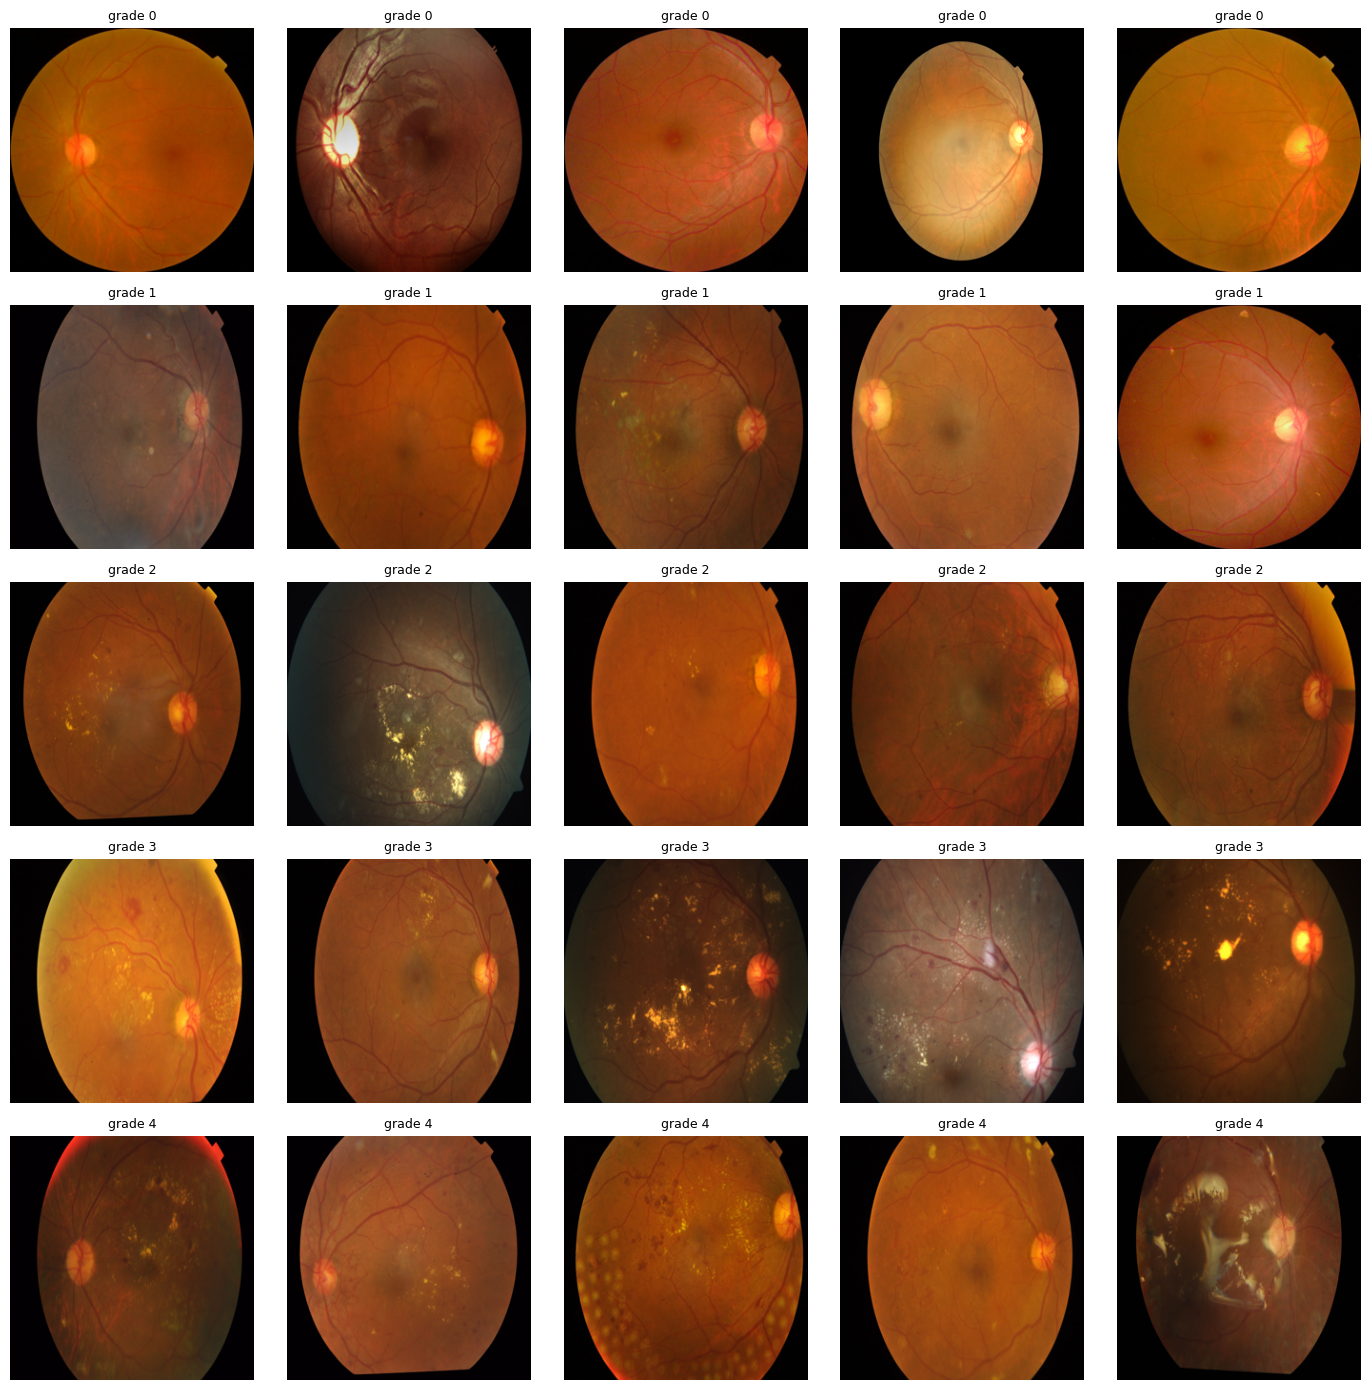

In [8]:
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['orig_path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info = pd.DataFrame(info)
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())

grades = sorted(train_df['orig_class'].unique())
fig, axes = plt.subplots(len(grades), 5, figsize=(14, 2.8 * len(grades)))
axes = np.atleast_2d(axes)
for r, g in enumerate(grades):
    sub = train_df[train_df.orig_class == g]
    paths = sub['orig_path'].sample(min(5, len(sub)), random_state=1)
    for ax in axes[r]:
        ax.axis('off')
    for ax, p in zip(axes[r], paths):
        with Image.open(p) as im:
            ax.imshow(im.convert('RGB').resize((256, 256)))
        ax.set_title(f'grade {g}', fontsize=9)
plt.tight_layout()
plt.show()

### Calculations from the output

Median image: $2144 \times 1536 = 3{,}293{,}184$ pixels. After caching, an image has $256 \times 256 = 65{,}536$ pixels:

$$\text{reduction} = \frac{3{,}293{,}184}{65{,}536} \approx 50\times$$

Median aspect ratio $= 2144/1536 = 1.40$, but the cached image is square ($1.00$), so the picture is slightly squeezed horizontally. This is acceptable because it is applied to every image identically.

All 300 sampled images are `RGB`, which confirms `GRAYSCALE = False`.

## 5. Resize once, hash and fingerprint every image

For each file (4 threads in parallel):

* **md5 hash** of the original bytes detects *exact* duplicates.
* The image is converted to RGB, resized once to $256 \times 256$ (bicubic) and saved to `/kaggle/working/cache`, so training never reads the giant originals again.
* A **fingerprint** is a $32 \times 32$ greyscale thumbnail, standardised so it is robust to resizing, re-compression and brightness changes:

$$
f = \frac{a - \mu_a}{\sigma_a + \varepsilon}, \qquad a \in \mathbb{R}^{32 \times 32},\ \varepsilon = 10^{-6},\ f \in \mathbb{R}^{1024}
$$

In [9]:
CACHE_DIR = '/kaggle/working/cache'
os.makedirs(CACHE_DIR, exist_ok=True)

def fingerprint(im, n=32):
    """32 x 32 grayscale thumbnail, standardized: robust to resizing,
    recompression, and brightness changes."""
    a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()

def preprocess(row):
    """md5 of the ORIGINAL file, resize once to CACHE_SIZE, save, fingerprint."""
    with open(row.orig_path, 'rb') as f:
        h = hashlib.md5(f.read()).hexdigest()
    out = os.path.join(CACHE_DIR, row.file + '.png')
    with Image.open(row.orig_path) as im:
        im = im.convert('RGB').resize((CACHE_SIZE, CACHE_SIZE), Image.Resampling.BICUBIC)
    if not os.path.exists(out):
        im.save(out)
    return out, h, fingerprint(im)

t0 = time.time()
with ThreadPoolExecutor(max_workers=4) as ex:
    res = list(ex.map(preprocess, train_df.itertuples()))
train_df['path'] = [r[0] for r in res]
train_df['md5'] = [r[1] for r in res]
FP = np.stack([r[2] for r in res])
print(f'Resized, hashed and fingerprinted {len(train_df)} images in {time.time() - t0:.0f}s')

Resized, hashed and fingerprinted 3662 images in 329s


### Calculations from the output

$$\frac{329\ \text{s}}{3662\ \text{images}} = 0.090\ \text{s per image} \;\Rightarrow\; \frac{3662}{329} \approx 11.1\ \text{images/s}$$

Fingerprint length: $32 \times 32 = 1024$ numbers per image, so the matrix `FP` has shape $3662 \times 1024$.

## 6. Remove exact duplicate files

Identical files that appear more than once inflate the dataset and, worse, can land in both train and test. Rules used:

* identical files with **different labels** are contradictory, so *every* copy is dropped;
* otherwise **one** copy is kept and the rest are removed.

In [10]:
exact = train_df[train_df.duplicated('md5', keep=False)]
print('Exact duplicate files:', len(exact))
print('Duplicate groups (sets of identical files):', exact['md5'].nunique())
if len(exact):
    print(exact.sort_values('md5')[['file', 'orig_class', 'md5']].head(20).to_string())
conflict = exact.groupby('md5')['label'].nunique()
conflict_md5 = set(conflict[conflict > 1].index)
print('Identical files with DIFFERENT labels:', len(conflict_md5))

# identical files with different labels -> drop every copy; otherwise keep one copy
keep = ~train_df['md5'].isin(conflict_md5) & ~train_df.duplicated('md5', keep='first')
print(f'Removed {(~keep).sum()} files; {keep.sum()} images remain')
train_df = train_df[keep.values].reset_index(drop=True)
FP = FP[keep.values]

Exact duplicate files: 251
Duplicate groups (sets of identical files): 123
              file orig_class                               md5
3312  012a242ac6ff          2  028d27ff645aaeb21688586fbb0e9299
439   1f07dae3cadb          2  028d27ff645aaeb21688586fbb0e9299
2919  cac40227d3b2          2  02e855cb5c1eb05c81e6fd027ccdbcf2
3315  0161338f53cc          2  02e855cb5c1eb05c81e6fd027ccdbcf2
797   38fe9f854046          2  05f30df45f7e07befe26b995f39cad64
422   1dfbede13143          2  05f30df45f7e07befe26b995f39cad64
2734  bd5013540a13          4  0a20d5b84db6d380d9ce66be03b3369c
487   22895c89792f          4  0a20d5b84db6d380d9ce66be03b3369c
1783  7e160c8b611e          3  165540476389b5d13f68c4468bcb4ed4
2074  91b6ebaa3678          3  165540476389b5d13f68c4468bcb4ed4
3569  14e3f84445f7          3  197303f49434137ed6ab3c9906d76a13
178   f0f89314e860          4  197303f49434137ed6ab3c9906d76a13
2111  94372043d55b          1  1a78b60bc76f0b2ddf72f50a62086ac8
3486  0dce95217626          1

### Calculations from the output

251 files fall into 123 duplicate groups, so the number of redundant copies is

$$251 - 123 = 128 .$$

6 groups carry contradictory labels, and for these even the one copy that would normally be kept is dropped, so 6 extra files go:

$$128 + 6 = 134 \text{ removed}, \qquad 3662 - 134 = 3528 \text{ images remain} \checkmark$$

The contradiction test compares the *binary* label, so two identical files graded 3 and 4 are both "referable" and are not counted as a conflict.

## 7. Near-duplicates and group construction (leakage control)

There is no patient id, so images of the same eye (re-photographed or re-compressed) are found from the fingerprints. The distance between two images is the **mean absolute difference** of their fingerprints:

$$
d(i,j) = \frac{1}{1024}\sum_{k=1}^{1024} \left| f_{i,k} - f_{j,k} \right|
$$

Pairs with $d < 0.10$ are linked, and a **union-find** (connected components) merges linked images into one *group*. A whole group is later sent to a single split, so the model never sees a near-copy of a test image during training.

The cell also prints the closest pairs and the pairs just below the threshold, so the threshold can be **inspected before it is trusted**.

Distance search done in 10s
Nearest-neighbour distance percentiles (1, 5, 25, 50): [0.048 0.061 0.079 0.109]
Near-duplicate pairs (distance < 0.1): 20748
Groups: 1998 | groups with more than 1 image: 51 | images in such groups: 1581
Near-duplicate groups whose images carry DIFFERENT grades: 20


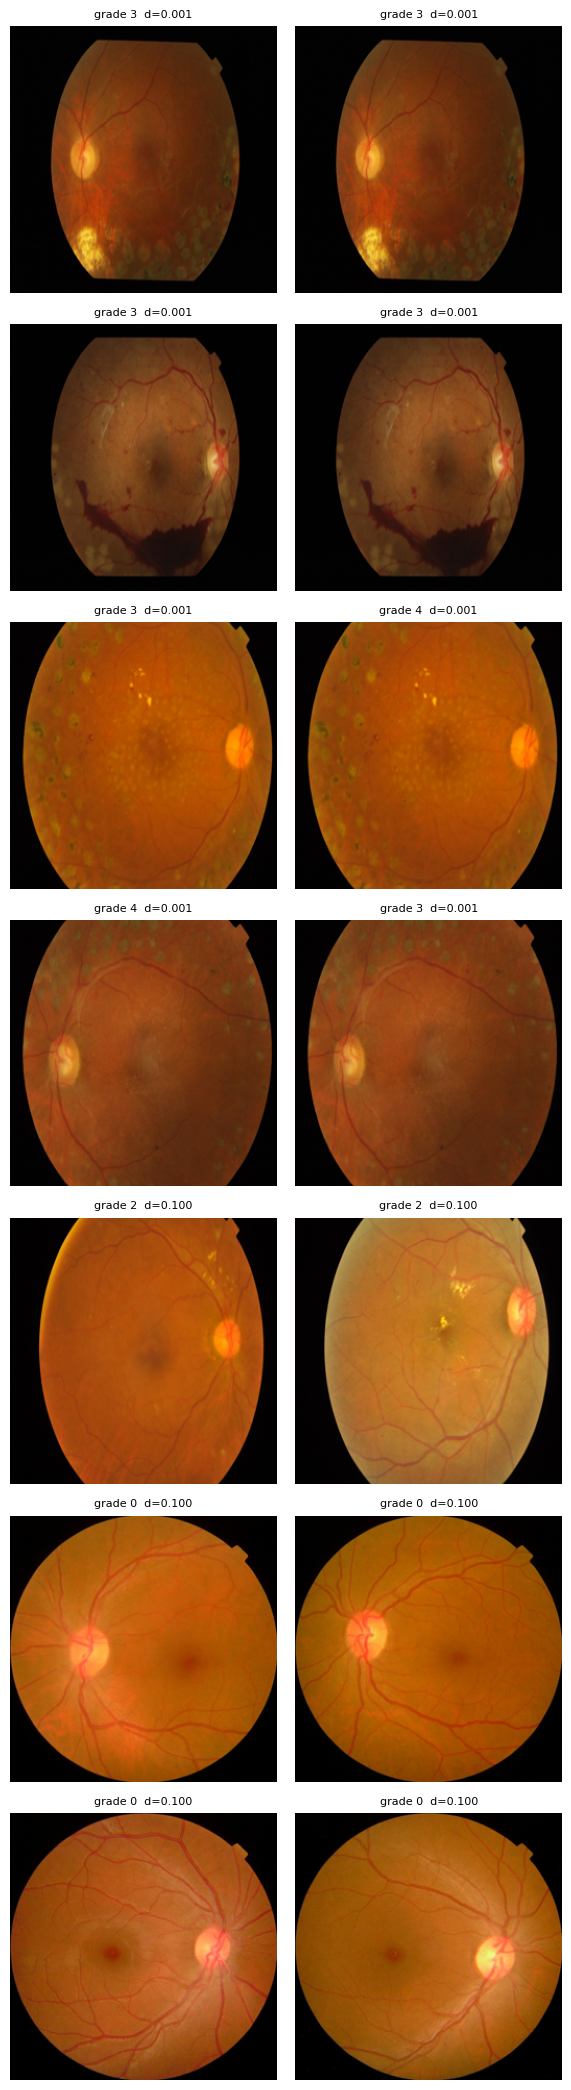

In [11]:
# Near-duplicates (same eye / same patient re-photographed, re-compressed copies).
# There is no patient id, so images closer than NEAR_DUP_THR are merged into one GROUP
# and a whole group always goes to the same split.
FPt = torch.tensor(FP, dtype=torch.float32, device=device)
N = len(FPt)
pairs, nn_dist = [], np.zeros(N, dtype=np.float32)
t0 = time.time()
for i in range(0, N, 256):
    d = torch.cdist(FPt[i:i + 256], FPt, p=1) / FPt.shape[1]
    r = torch.arange(len(d), device=device)
    d[r, r + i] = float('inf')                       # ignore self
    nn_dist[i:i + len(d)] = d.min(1).values.cpu().numpy()
    ii, jj = torch.where(d < NEAR_DUP_THR)
    for a, b in zip((ii + i).tolist(), jj.tolist()):
        if a < b:
            pairs.append((a, b, float(d[a - i, b])))
print(f'Distance search done in {time.time() - t0:.0f}s')
print('Nearest-neighbour distance percentiles (1, 5, 25, 50):',
      np.percentile(nn_dist, [1, 5, 25, 50]).round(3))
print(f'Near-duplicate pairs (distance < {NEAR_DUP_THR}): {len(pairs)}')

parent = list(range(N))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
for a, b, _ in pairs:
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[ra] = rb
train_df['group'] = [find(i) for i in range(N)]

gsize = train_df.groupby('group').size()
print(f'Groups: {len(gsize)} | groups with more than 1 image: {(gsize > 1).sum()} '
      f'| images in such groups: {gsize[gsize > 1].sum()}')
gdiff = train_df.groupby('group')['orig_class'].nunique()
print('Near-duplicate groups whose images carry DIFFERENT grades:', int((gdiff > 1).sum()))

# Inspect the closest pairs and the pairs just under the threshold BEFORE trusting the threshold
pairs.sort(key=lambda t: t[2])
show = pairs[:4] + pairs[-3:] if len(pairs) > 7 else pairs
if show:
    fig, axes = plt.subplots(len(show), 2, figsize=(6, 3 * len(show)))
    axes = np.atleast_2d(axes)
    for r, (a, b, dd) in enumerate(show):
        for c, k in enumerate((a, b)):
            row = train_df.iloc[k]
            axes[r, c].imshow(Image.open(row['path']))
            axes[r, c].set_title(f"grade {row['orig_class']}  d={dd:.3f}", fontsize=8)
            axes[r, c].axis('off')
    plt.tight_layout()
    plt.show()

### Calculations from the output

**Image counts per group**

$$3528 - 1581 = 1947 \text{ singletons}, \qquad 1947 + 51 = 1998 \text{ groups} \checkmark$$

$$\text{share of images in multi-image groups} = \frac{1581}{3528} = 44.8\,\%$$

Average size of a multi-image group: $1581 / 51 \approx 31$ images.

**Consistency with the percentiles.** The median nearest-neighbour distance is $0.109 > 0.10$, so a bit more than half the images have no neighbour below the threshold, which matches about $45\,\%$ being grouped.

**Warning sign.** There are 20,748 linked pairs but only 51 groups, so linking is *transitive* (chaining), and 20 groups contain images with different grades. The threshold is therefore somewhat loose: some groups probably merge different eyes. This is the safe direction for leakage (groups are too big, not too small), but it makes the splits uneven, as the next cell shows.

## 8. Stratified, grouped train / validation / test split

`StratifiedGroupKFold` keeps every group inside one split while keeping the DR-grade mix similar:

1. 6 folds: one fold is the **test** set (ideal share $1/6$).
2. On the remaining part, 5 folds: one fold is the **validation** set (ideal share $1/5 \cdot 5/6 = 1/6$ of the total).
3. The rest is **training**.

The three `Groups shared by ...` counters must all be **0**, which proves there is no leakage between splits. The assignment is saved to `splits.csv`.

In [12]:
# Validation + test split: stratified by DR GRADE, grouped by near-duplicate group, fixed seed.
# 6 folds -> test = 1/6; then 5 folds on the rest -> val = 1/6 of the total.
strat = train_df['orig_class']
sgkf6 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
trval_idx, te_idx = next(sgkf6.split(train_df, strat, train_df['group']))
trval_df = train_df.iloc[trval_idx].reset_index(drop=True)
test_df = train_df.iloc[te_idx].reset_index(drop=True)

sgkf5 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf5.split(trval_df, trval_df['orig_class'], trval_df['group']))
tr_df = trval_df.iloc[tr_idx].reset_index(drop=True)
va_df = trval_df.iloc[va_idx].reset_index(drop=True)

print(f'train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Groups shared by train and val: ', len(set(tr_df.group) & set(va_df.group)))     # must be 0
print('Groups shared by train and test:', len(set(tr_df.group) & set(test_df.group)))   # must be 0
print('Groups shared by val and test:  ', len(set(va_df.group) & set(test_df.group)))   # must be 0
print(pd.DataFrame({'train': tr_df.orig_class.value_counts(),
                    'val': va_df.orig_class.value_counts(),
                    'test': test_df.orig_class.value_counts()}).sort_index().to_string())
print('Val labels:', va_df['label'].value_counts().to_dict(),
      '| Test labels:', test_df['label'].value_counts().to_dict())

pd.concat([tr_df.assign(split='train'), va_df.assign(split='val'), test_df.assign(split='test')])[
    ['file', 'orig_class', 'label', 'group', 'split']].to_csv('/kaggle/working/splits.csv', index=False)

train 1970 | val 1052 | test 506
Groups shared by train and val:  0
Groups shared by train and test: 0
Groups shared by val and test:   0
            train  val  test
orig_class                  
0             871  837    90
1             236   55    49
2             551  111   266
3             125   24    33
4             187   25    68
Val labels: {'non_referable': 892, 'referable_DR': 160} | Test labels: {'referable_DR': 367, 'non_referable': 139}


### Calculations from the output

**Sizes:** $1970 + 1052 + 506 = 3528 \checkmark$

| Split | Ideal ($3528/6$ or $4 \times 3528/6$) | Actual | Share |
|---|---|---|---|
| train | 2352 (66.7 %) | 1970 | $1970/3528 = 55.8\,\%$ |
| val | 588 (16.7 %) | 1052 | $1052/3528 = 29.8\,\%$ |
| test | 588 (16.7 %) | 506 | $506/3528 = 14.3\,\%$ |

The sizes miss the ideal because groups are indivisible (one very large group lands in validation).

**Referable prevalence in each split** (grades 2 + 3 + 4):

$$\text{train: } \frac{551+125+187}{1970} = \frac{863}{1970} = 43.8\,\%$$

$$\text{val: } \frac{111+24+25}{1052} = \frac{160}{1052} = 15.2\,\%$$

$$\text{test: } \frac{266+33+68}{506} = \frac{367}{506} = 72.5\,\%$$

**Important caveat:** the three splits have very different class mixes (15 % vs 44 % vs 73 % positives). Metrics that depend on prevalence (accuracy, PPV, weighted F1) are therefore *not comparable* between validation and test, and the threshold picked on validation may shift on test.

## 9. Transforms, augmentation and `Dataset`

**Normalisation** with the ImageNet statistics (what the pretrained weights expect), per channel $c$:

$$x'_c = \frac{x_c - \mu_c}{\sigma_c}, \qquad \mu = (0.485, 0.456, 0.406),\ \sigma = (0.229, 0.224, 0.225)$$

Example: a red pixel of $0.5$ becomes $(0.5 - 0.485)/0.229 = 0.066$.

**Training augmentation** (random, new every epoch): random resized crop (scale 0.8 to 1.0), horizontal and vertical flips, rotation up to $20^\circ$, and brightness/contrast jitter of $\pm 15\,\%$. Hue and saturation are **not** jittered because colour is disease evidence.

**Validation and test** use only a deterministic resize to $224 \times 224$ plus normalisation, so the measurements are repeatable.

`ImageTable` reads a cached PNG and maps the label to an index using the class order `['non_referable', 'referable_DR']` (index 0 and 1).

In [13]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),   # no hue/saturation: colour is disease evidence
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img = img.convert('L' if GRAYSCALE else 'RGB')
        return self.tf(img), self.y[i]

train_ds = ImageTable(tr_df, train_tf)
val_ds = ImageTable(va_df, eval_tf)
test_ds = ImageTable(test_df, eval_tf)
print(f'train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)}')
print('Class order:', classes)

train 1970 | val 1052 | test 506
Class order: ['non_referable', 'referable_DR']


## 10. Class weights and data loaders

To stop the majority class from dominating the loss, each class gets the weight

$$
w_c = \frac{N}{K \cdot n_c}
$$

where $N$ is the number of training images, $K$ the number of classes and $n_c$ the images in class $c$. Rare classes get weights above 1, common classes below 1. A weighted loss is used here; the alternative (`USE_SAMPLER = True`) draws balanced batches with $P(i) \propto 1/n_{c(i)}$.

In [14]:
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)        # N / (K * n_c)
print('Images per class in train:', dict(zip(classes, n_c)))
print('Class weights:', dict(zip(classes, class_w.round(3))))
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)

USE_SAMPLER = False     # try True later: balanced batches instead of weighted loss
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]                     # P(i) ~ 1 / n_class(i)
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

Images per class in train: {'non_referable': np.int64(1107), 'referable_DR': np.int64(863)}
Class weights: {'non_referable': np.float64(0.89), 'referable_DR': np.float64(1.141)}


### Calculations from the output

$N = 1970$, $K = 2$, $n_{\text{non-ref}} = 1107$, $n_{\text{ref}} = 863$:

$$w_{\text{non-ref}} = \frac{1970}{2 \times 1107} = \frac{1970}{2214} = 0.890$$

$$w_{\text{ref}} = \frac{1970}{2 \times 863} = \frac{1970}{1726} = 1.141$$

**Check:** every class should contribute the same total weight $N/K = 985$:

$$1107 \times 0.8898 = 985.0, \qquad 863 \times 1.1413 = 985.0 \checkmark$$

The positive class is up-weighted by $w_{\text{ref}} / w_{\text{non-ref}} = 1107/863 = 1.28\times$.

## 11. Build the pretrained ResNet-18 and freeze the body

**Transfer learning:** start from ImageNet weights (found locally as `resnet18-f37072fd.pth`, so no internet is needed), replace the final fully connected layer by a new 2-class layer, and **freeze** every other parameter. Only the new head is trained first.

`load_local` copies only tensors whose names and shapes match and prints what was skipped. Here all 102 tensors of the ImageNet checkpoint matched (nothing skipped, no missing keys), and only *afterwards* is the 1000-class `fc` replaced by the new 2-class head.

In [15]:
def find_weights(name):
    """Search /kaggle/input (recursively) and the torch cache for a .pth/.pt file of this backbone."""
    key = name.replace('_', '').replace('-', '').lower()
    roots = ['/kaggle/input', os.path.expanduser('~/.cache/torch/hub/checkpoints')]
    hits = []
    for root in roots:
        for dp, _, fs in os.walk(root):
            for f in fs:
                if f.lower().endswith(('.pth', '.pt')):
                    full = os.path.join(dp, f)
                    if key in full.lower().replace('_', '').replace('-', ''):
                        hits.append(full)
    # prefer the official ImageNet file (e.g. resnet18-f37072fd.pth) over fine-tuned ones
    pref = name.replace('_', '') + '-'
    hits.sort(key=lambda p: (not os.path.basename(p).lower().startswith(pref), p))
    print('Weight files found:', hits)
    if not hits:
        mdir = '/kaggle/input/models'
        print('Nothing matched. /kaggle/input contains:', os.listdir('/kaggle/input')
              if os.path.isdir('/kaggle/input') else 'N/A')
        if os.path.isdir(mdir):
            for dp, _, fs in os.walk(mdir):
                for f in fs:
                    print('  model file:', os.path.join(dp, f))
    return hits[0] if hits else None

def load_local(m, path):
    """Load a .pth/.pt file into model m, skipping any tensor whose shape does not match
    (e.g. the 1000-class or 6-class fc layer of a different checkpoint)."""
    obj = torch.load(path, map_location='cpu', weights_only=False)
    if isinstance(obj, nn.Module):                 # file holds a whole model
        obj = obj.state_dict()
    if isinstance(obj, dict) and 'state_dict' in obj:
        obj = obj['state_dict']
    obj = {k.replace('module.', ''): v for k, v in obj.items()}
    own = m.state_dict()
    ok = {k: v for k, v in obj.items() if k in own and own[k].shape == v.shape}
    skipped = [k for k in obj if k not in ok]
    result = m.load_state_dict(ok, strict=False)
    print('Loaded', len(ok), 'tensors from', os.path.basename(path))
    print('Skipped (shape/name mismatch):', skipped)
    print('Missing keys:', result.missing_keys)
    return m

def get_backbone(name, ctor, weights_enum):
    local = find_weights(name)
    if local:
        return load_local(ctor(weights=None), local)
    try:                                           # needs internet
        return ctor(weights=weights_enum.DEFAULT)
    except Exception as e:
        raise RuntimeError(
            f'No local {name} weights found and the download failed ({type(e).__name__}). '
            f'Fix: in the Kaggle sidebar click "Add Input" -> Models -> search "{name}" '
            f'(PyTorch) and add it, OR turn on Settings -> Internet.') from None

def build_model(name, n_classes):
    if name == 'resnet18':
        m = get_backbone(name, models.resnet18, models.ResNet18_Weights)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'resnet50':
        m = get_backbone(name, models.resnet50, models.ResNet50_Weights)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'efficientnet_b0':
        m = get_backbone(name, models.efficientnet_b0, models.EfficientNet_B0_Weights)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last = m, m.classifier, m.features[-1]
    else:
        raise ValueError(name)
    for p in body.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    return m.to(device), head, last

model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:',
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Weight files found: ['/kaggle/input/models/najeebkhan123342/resnet-18/pytorch/default/1/resnet18-f37072fd.pth']
Loaded 102 tensors from resnet18-f37072fd.pth
Skipped (shape/name mismatch): []
Missing keys: []
resnet18 trainable: 1026


### Calculations from the output

New head: $512 \text{ inputs} \times 2 \text{ outputs} + 2 \text{ biases}$:

$$512 \times 2 + 2 = 1026 \text{ trainable parameters} \checkmark$$

ResNet-18 has $11{,}689{,}512$ parameters with a 1000-class head; the 1000-class `fc` has $512 \times 1000 + 1000 = 513{,}000$. With a 2-class head:

$$11{,}689{,}512 - 513{,}000 + 1026 = 11{,}177{,}538 \text{ parameters in total}$$

$$\text{trainable share} = \frac{1026}{11{,}177{,}538} \approx 0.009\,\%$$

Training only 0.009 % of the weights is fast and hard to overfit on 1970 images.

## 12. Training in two phases

**Softmax and weighted cross-entropy** (the class weights from section 10; PyTorch's weighted mean):

$$
p_{i,c} = \frac{e^{z_{i,c}}}{\sum_{k} e^{z_{i,k}}}, \qquad
\mathcal{L} = - \frac{\sum_i w_{y_i} \log p_{i,y_i}}{\sum_i w_{y_i}}
$$

**Phase 1 (head only):** Adam, learning rate $10^{-3}$, 2 epochs.
**Phase 2 (fine-tune):** unfreeze `layer4`, learning rate $10^{-4}$ for it and $10^{-3}$ for the head, 3 epochs. The smaller rate protects the pretrained features.

**Model selection:** after each epoch the validation **macro-F1** is computed (not accuracy), and the best weights are restored at the end:

$$\text{macro-F1} = \frac{1}{K}\sum_{c=1}^{K} F1_c, \qquad F1_c = \frac{2\,P_c R_c}{P_c + R_c}$$

In [16]:
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')      # not accuracy
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)
    return best

print('Phase 1: head only')
fit(model, head.parameters(), epochs=2, lr=1e-3)
print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
    p.requires_grad = True
fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
            {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)

Phase 1: head only
epoch 1: val macro-F1 0.806 (176s)
epoch 2: val macro-F1 0.818 (173s)
Phase 2: fine-tune the last block
epoch 1: val macro-F1 0.887 (224s)
epoch 2: val macro-F1 0.898 (223s)
epoch 3: val macro-F1 0.919 (222s)


0.919274443056678

### Calculations from the output

| Phase | Epoch | Val macro-F1 |
|---|---|---|
| head only | 1 | 0.806 |
| head only | 2 | 0.818 |
| fine-tune | 1 | 0.887 |
| fine-tune | 2 | 0.898 |
| fine-tune | 3 | **0.919** |

**Gain from unfreezing the last block:**

$$0.919 - 0.818 = +0.101 \quad (\approx 10\ \text{percentage points})$$

**Training time:** $176 + 173 + 224 + 223 + 222 = 1018\ \text{s} \approx 17\ \text{minutes}$. Phase 2 epochs cost about $224/175 = 1.28\times$ more because gradients now flow through `layer4`.

Validation macro-F1 was still rising at the last epoch, so the model is probably **not fully converged**; more epochs would likely help.

## 13. Test-set report (argmax, i.e. threshold 0.5)

The test set is touched **once**, after model selection. For each class $c$:

$$
P_c = \frac{TP_c}{TP_c + FP_c}, \qquad
R_c = \frac{TP_c}{TP_c + FN_c}, \qquad
F1_c = \frac{2P_cR_c}{P_c + R_c}
$$

$$
\text{accuracy} = \frac{TP + TN}{N}, \qquad
\text{macro-F1} = \frac{F1_1 + F1_2}{2}, \qquad
\text{weighted-F1} = \sum_c \frac{n_c}{N} F1_c
$$

               precision    recall  f1-score   support

non_referable      0.871     0.777     0.821       139
 referable_DR      0.919     0.956     0.937       367

     accuracy                          0.907       506
    macro avg      0.895     0.867     0.879       506
 weighted avg      0.906     0.907     0.905       506

Macro-F1: 0.879


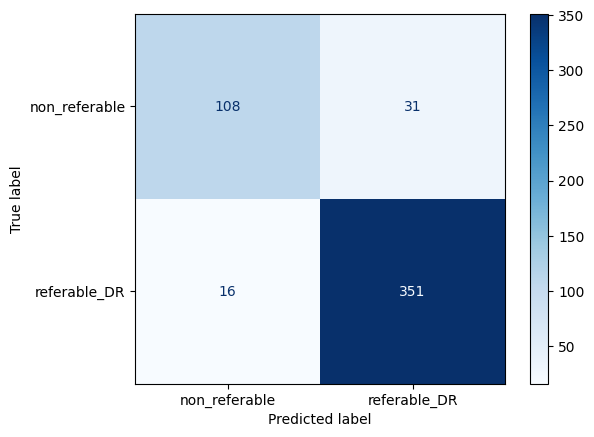

In [17]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
print('Macro-F1:', round(f1_score(y_test, pred, average='macro'), 3))
if not BINARY:      # the competition metric: quadratic weighted kappa on the 0-4 grade
    print('Quadratic weighted kappa:', round(cohen_kappa_score(y_test, pred, weights='quadratic'), 3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=classes).plot(cmap='Blues')
plt.show()

### Calculations from the output

**Confusion matrix reconstructed from recall $\times$ support** (rows = true, columns = predicted):

| | pred non_ref | pred referable |
|---|---|---|
| true non_ref (139) | $TN = 0.777 \times 139 \approx 108$ | $FP = 139 - 108 = 31$ |
| true referable (367) | $FN = 367 - 351 = 16$ | $TP = 0.956 \times 367 \approx 351$ |

**Check precision:**

$$P_{\text{ref}} = \frac{351}{351 + 31} = 0.919, \qquad P_{\text{non-ref}} = \frac{108}{108 + 16} = 0.871 \checkmark$$

**F1 per class:**

$$F1_{\text{non-ref}} = \frac{2 \times 0.871 \times 0.777}{0.871 + 0.777} = 0.821, \qquad
F1_{\text{ref}} = \frac{2 \times 0.919 \times 0.956}{0.919 + 0.956} = 0.937$$

**Accuracy, macro and weighted F1:**

$$\text{accuracy} = \frac{108 + 351}{506} = 0.907$$

$$\text{macro-F1} = \frac{0.821 + 0.937}{2} = 0.879$$

$$\text{weighted-F1} = \frac{139 \times 0.821 + 367 \times 0.937}{506} = \frac{114.1 + 343.9}{506} = 0.905$$

Weighted-F1 (0.905) is higher than macro-F1 (0.879) because 72.5 % of the test images are the easier referable class. The weak spot is the **non-referable recall of 0.777**: about 22 % of healthy or mild eyes are sent for referral.

## 14. Choose a high-recall operating threshold on validation

A screening tool must miss as few referable eyes as possible. The threshold $t$ is chosen **on the validation set** as the highest value that still reaches the target recall (0.95), then applied unchanged to the test set (no tuning on test data):

$$
\hat y_i = \mathbb{1}\left[\, p_i(\text{referable}) \ge t \,\right]
$$

**Screening metrics**

$$
\text{Sensitivity} = \frac{TP}{TP + FN}, \quad
\text{Specificity} = \frac{TN}{TN + FP}, \quad
\text{PPV} = \frac{TP}{TP + FP}, \quad
\text{NPV} = \frac{TN}{TN + FN}
$$

PPV also depends on the **prevalence** $\pi$ (Bayes' rule):

$$
\text{PPV} = \frac{\text{Sens} \cdot \pi}{\text{Sens} \cdot \pi + (1 - \text{Spec})(1 - \pi)}
$$

The cell finally shows what share of each DR grade is flagged.

In [18]:
if len(classes) == 2:
    pos = classes.index(POSITIVE)
    p_val, y_val = predict(model, val_dl)
    fpr, tpr, thr = roc_curve(y_val == pos, p_val[:, pos])
    t = thr[np.argmax(tpr >= TARGET_RECALL)]     # highest t reaching target
    print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: '
          f'{t:.3f}')

    s = p_test[:, pos]
    yp, yt = s >= t, y_test == pos
    tp, fn = (yp & yt).sum(), (~yp & yt).sum()
    tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
    print(f'TP {tp} | FN {fn} | TN {tn} | FP {fp}')
    print(f'Test prevalence of {POSITIVE}: {yt.mean():.3f}')
    print(f'Test AUC {roc_auc_score(yt, s):.3f}')
    print(f'Sensitivity {tp / (tp + fn):.3f}   Specificity {tn / (tn + fp):.3f}'
          f'   PPV {tp / max(tp + fp, 1):.3f}')

    print(f'\nShare of test images flagged as {POSITIVE}, by DR grade:')
    g_test = test_df['orig_class'].values
    for g in sorted(set(g_test)):
        m = g_test == g
        print(f'  grade {g}: n={m.sum():4d}  flagged {yp[m].mean():.3f}')

Threshold chosen on VALIDATION for recall >= 0.95: 0.464
TP 355 | FN 12 | TN 107 | FP 32
Test prevalence of referable_DR: 0.725
Test AUC 0.956
Sensitivity 0.967   Specificity 0.770   PPV 0.917

Share of test images flagged as referable_DR, by DR grade:
  grade 0: n=  90  flagged 0.044
  grade 1: n=  49  flagged 0.571
  grade 2: n= 266  flagged 0.966
  grade 3: n=  33  flagged 1.000
  grade 4: n=  68  flagged 0.956


### Calculations from the output

$t = 0.464$ (slightly below 0.5, so more images are called referable). Test counts: $TP = 355,\ FN = 12,\ TN = 107,\ FP = 32$.

$$\text{Prevalence} = \frac{355 + 12}{506} = \frac{367}{506} = 0.725 \checkmark$$

$$\text{Sensitivity} = \frac{355}{355 + 12} = \frac{355}{367} = 0.967$$

$$\text{Specificity} = \frac{107}{107 + 32} = \frac{107}{139} = 0.770$$

$$\text{PPV} = \frac{355}{355 + 32} = \frac{355}{387} = 0.917, \qquad
\text{NPV} = \frac{107}{107 + 12} = \frac{107}{119} = 0.899$$

**PPV through Bayes' rule (same answer):**

$$\text{PPV} = \frac{0.967 \times 0.725}{0.967 \times 0.725 + 0.230 \times 0.275} = \frac{0.7011}{0.7011 + 0.0633} = 0.917 \checkmark$$

**Effect of the threshold vs. argmax (section 13):** FN fell from 16 to 12 and sensitivity rose from $351/367 = 0.956$ to $0.967$, at the cost of specificity $0.777 \to 0.770$ (FP $31 \to 32$). The validation target of 0.95 was met on the test set (0.967).

**Flagged images per grade** (share $\times$ n):

| Grade | n | flagged | count |
|---|---|---|---|
| 0 | 90 | 0.044 | 4 |
| 1 | 49 | 0.571 | 28 |
| 2 | 266 | 0.966 | 257 |
| 3 | 33 | 1.000 | 33 |
| 4 | 68 | 0.956 | 65 |

$$4 + 28 + 257 + 33 + 65 = 387 = TP + FP \checkmark, \qquad FP = 4 + 28 = 32 \checkmark \;(\text{grades 0 and 1})$$

$$FN = (266 - 257) + 0 + (68 - 65) = 12 \checkmark$$

Mild DR (grade 1) is the hard boundary: 57 % of it is flagged although it is not "referable" by the label rule.

**What if screening were done in the general population (prevalence $\pi = 2\,\%$)?**

$$\text{PPV} = \frac{0.967 \times 0.02}{0.967 \times 0.02 + 0.230 \times 0.98} = \frac{0.0193}{0.0193 + 0.2254} = 0.079$$

so only about 8 % of flagged patients would truly be referable, even though the test PPV looks like 92 %.

## 15. Grad-CAM implementation

Grad-CAM shows **which image regions drove a prediction**. Forward and backward hooks on the last convolution block (`layer4`) store the activations $A^k$ and the gradients of the class score $y^c$:

$$
\alpha_k^{c} = \frac{1}{Z}\sum_{i}\sum_{j} \frac{\partial y^{c}}{\partial A^{k}_{ij}}, \qquad
L^{c}_{\text{Grad-CAM}} = \operatorname{ReLU}\!\Big(\sum_{k} \alpha_k^{c} A^{k}\Big)
$$

* $\alpha_k^c$: importance of feature map $k$ for class $c$ (global average of its gradients).
* $Z$: number of spatial positions in the map.
* ReLU keeps only evidence *for* the class.
* The map is bilinearly up-sampled to the input size and divided by its maximum, so values lie in $[0, 1]$.

`requires_grad` is switched back on for all parameters because the gradients must flow through the whole network. For a $224 \times 224$ input, ResNet-18's total stride is 32, so $Z = (224/32)^2 = 7 \times 7 = 49$ and the heat map is up-sampled by a factor of 32.

In [19]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._save_act)
        layer.register_full_backward_hook(self._save_grad)
    def _save_act(self, m, i, o):
        self.acts = o.detach()
    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)      # (1/Z) sum dy/dA
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()     # ReLU(sum a*A)
        cam = F.interpolate(cam[None, None], size=x.shape[-2:],
                            mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls

for p in model.parameters():
    p.requires_grad = True
cam = GradCAM(model, last_block)

## 16. Visual check: correct predictions and mistakes

For one **correctly** classified test image per DR grade (5 images) plus up to **4 mistakes**, the heat map is overlaid on the photo ($\alpha = 0.4$, `jet` colormap: red = most influential).

**What to look for**

* Good sign: attention on the retina itself, on lesions such as microaneurysms, haemorrhages, hard exudates and neovascularisation.
* Bad sign (shortcut learning): attention on the image border, the black background, text or a camera or hospital marker. That would mean the score reflects the acquisition source, not the disease, and the metrics above would be unreliable.

Heat maps are computed for the *predicted* class. The grid has $3 \times 4 = 12$ slots; $5 + 4 = 9$ are filled and the rest stay blank.

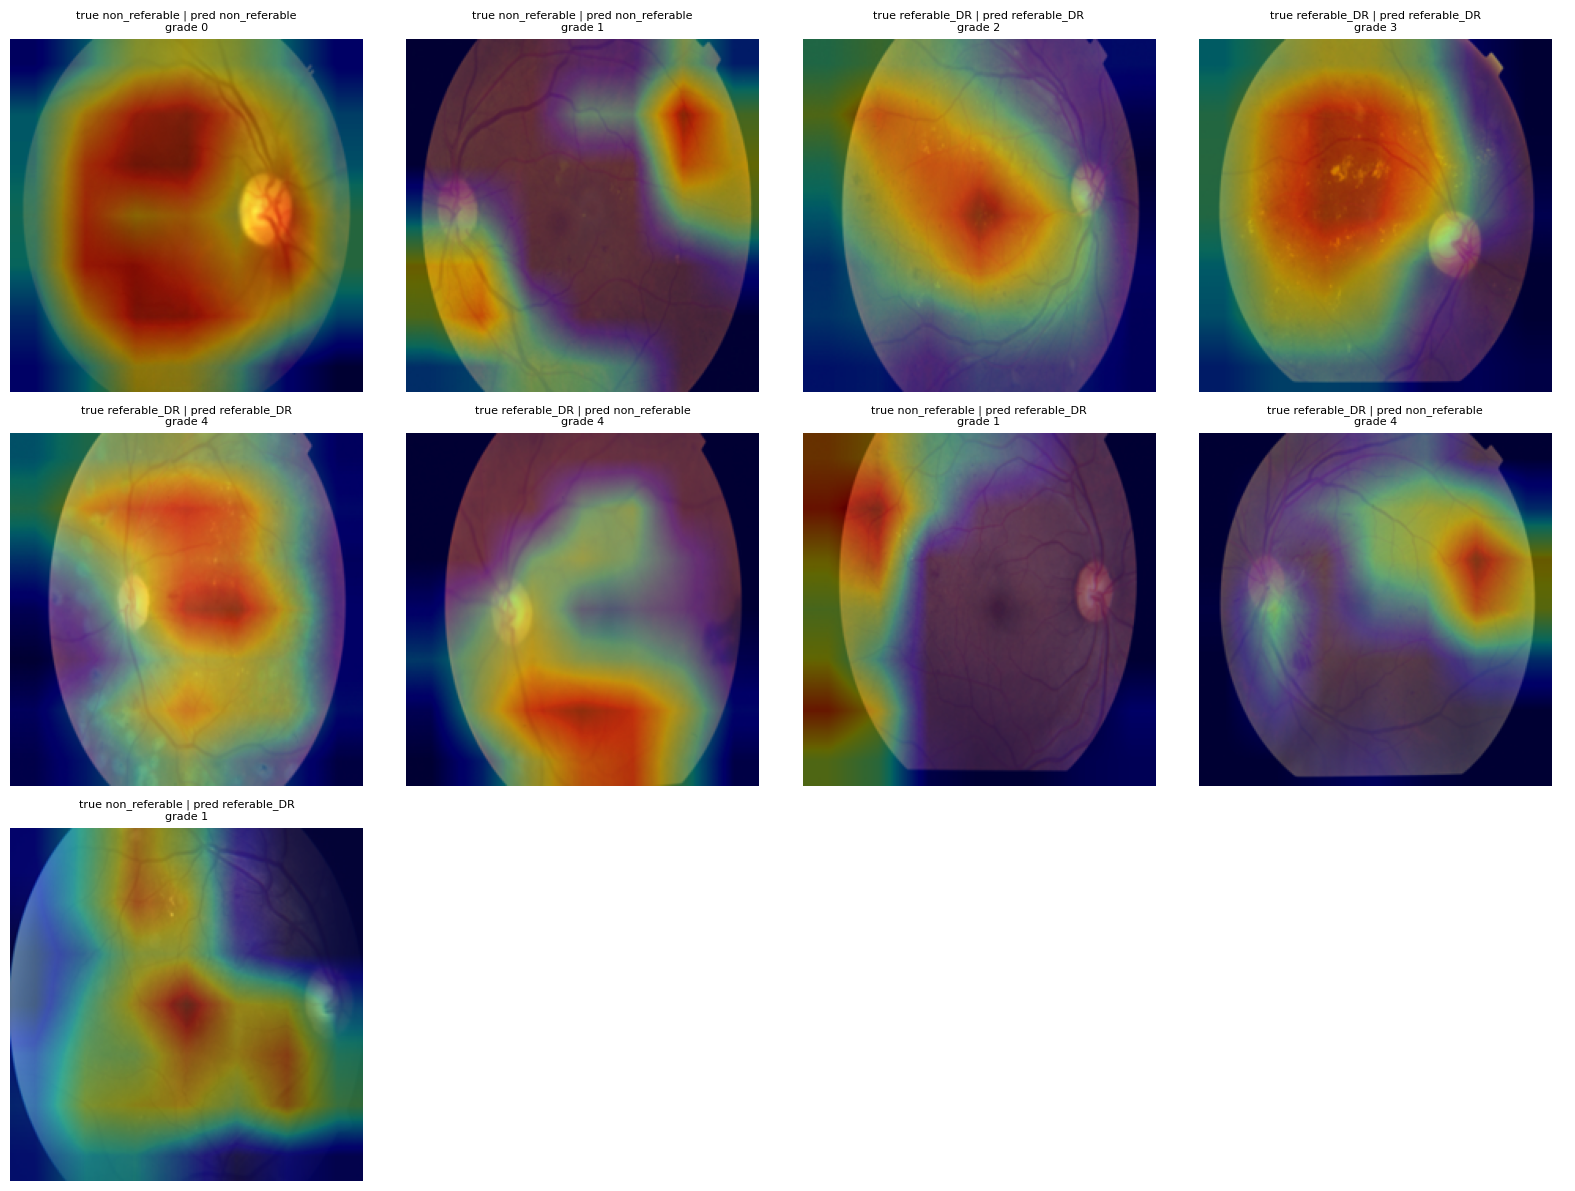

In [20]:
rng = np.random.default_rng(0)
orig = test_df['orig_class'].values
right_pool = np.where(pred == y_test)[0]
wrong_pool = np.where(pred != y_test)[0]
# one correctly classified example per DR grade, plus up to 4 mistakes
right = [int(rng.choice(right_pool[orig[right_pool] == c]))
         for c in sorted(set(orig)) if (orig[right_pool] == c).any()]
wrong = rng.choice(wrong_pool, size=min(4, len(wrong_pool)), replace=False).tolist()
idx = right + wrong

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, idx):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true {classes[y]} | pred {classes[c]}\ngrade {test_df.orig_class[i]}', fontsize=8)
plt.tight_layout()
plt.show()

## 17. Save the model for deployment

The checkpoint stores the weights **and** all information needed to rebuild the pipeline without guessing: class names and order, backbone, input size, grayscale flag, binary flag, positive class and the referable grade threshold. The data split is already saved in `splits.csv`, so the experiment can be reproduced exactly.

> Reminder: the operating threshold $t = 0.464$ is **not** stored in the checkpoint and has to be recorded separately before any use.

In [23]:
torch.save({'state_dict': model.state_dict(), 'classes': classes,
            'backbone': BACKBONE, 'img_size': IMG_SIZE,
            'grayscale': GRAYSCALE, 'binary': BINARY,
            'positive': POSITIVE if BINARY else None,
            'referable_min_grade': REFERABLE_MIN_GRADE}, '/kaggle/working/aptos_model.pt')
print('Saved aptos_model.pt (splits are in splits.csv)')

Saved aptos_model.pt (splits are in splits.csv)


# Lab 6 – Answers

## 1. Why does a random split of chest X-rays overestimate performance?

**Reason: data leakage between train and test.** A chest-X-ray collection contains *several images per patient* (follow-ups, frontal and lateral views), plus duplicates and images from the same hospital and scanner. A random image-level split puts some of a patient's images in training and others in the test set.

* The model can recognise the **patient** (heart size, implants, scars, tubes, body shape) or the **acquisition source** (scanner, hospital marker, contrast) and the matching label, instead of learning the disease. That is memorisation, and it scores well on the "unseen" images that are in fact siblings of training images.
* Test samples are therefore **not independent** of the training data, so the test score is biased upwards and does not predict performance on *new patients*.

**Working (example).** For a patient with 4 films and a 70/15/15 random split, each of the other 3 films is *not* in training with probability $0.30$, so a given test film has at least one training sibling with probability

$$1 - 0.30^{3} = 1 - 0.027 = 0.973 \approx 97\,\%.$$

(In a public set such as ChestX-ray14 with about $112{,}120$ images from $30{,}805$ patients, there are $112{,}120/30{,}805 \approx 3.6$ images per patient, so this situation is the norm.)

**Fix:** split by **patient** (and ideally by hospital): `GroupKFold` / `StratifiedGroupKFold` with the patient id as the group. **Evidence from this notebook (same principle on fundus photos):** 251 exact duplicate files and $1581/3528 = 44.8\,\%$ of images in near-duplicate groups would have crossed splits with a random split; the grouped split gives **0** shared groups between train, val and test.

---

## 2. Class weights for 900 and 100 training images

Formula: $w_c = \dfrac{N}{K \cdot n_c}$ with $N = 900 + 100 = 1000$ and $K = 2$.

$$w_{900} = \frac{1000}{2 \times 900} = \frac{1000}{1800} = 0.556$$

$$w_{100} = \frac{1000}{2 \times 100} = \frac{1000}{200} = 5.0$$

**Check:** each class contributes the same total weight $N/K = 500$:
$900 \times 0.556 = 500$ and $100 \times 5.0 = 500$. The minority class is weighted $5.0 / 0.556 = 9\times$ more per image, which equals the ratio of class sizes $900/100 = 9$.

---

## 3. Focal loss with $\gamma = 2$ and $p_t = 0.8$

Focal loss: $\;FL(p_t) = -(1 - p_t)^{\gamma} \log(p_t)$, so compared with cross-entropy $CE = -\log p_t$ the modulating factor is $(1 - p_t)^{\gamma}$.

$$(1 - 0.8)^{2} = 0.2^{2} = 0.04$$

The example is **down-weighted by a factor of 0.04, i.e. 25 times smaller** ($1/0.04 = 25$).

**In loss values:** $CE = -\ln 0.8 = 0.223$ and $FL = 0.04 \times 0.223 = 0.0089$.

**For contrast**, a hard example with $p_t = 0.1$ keeps a factor $(1 - 0.1)^2 = 0.81$ (almost full weight), so training focuses on hard, misclassified cases. (This notebook uses class-weighted cross-entropy, not focal loss.)

---

## 4. PPV with sensitivity 0.90, specificity 0.95, prevalence 2 %

$$\text{PPV} = \frac{\text{Sens} \times \pi}{\text{Sens} \times \pi + (1 - \text{Spec})(1 - \pi)}$$

$$\text{numerator} = 0.90 \times 0.02 = 0.018$$

$$\text{false positive term} = (1 - 0.95)(1 - 0.02) = 0.05 \times 0.98 = 0.049$$

$$\text{PPV} = \frac{0.018}{0.018 + 0.049} = \frac{0.018}{0.067} = 0.269 \approx 26.9\,\%$$

**Check with 10,000 people:** diseased $= 200$, healthy $= 9{,}800$; $TP = 0.90 \times 200 = 180$; $FP = 0.05 \times 9{,}800 = 490$.

$$\text{PPV} = \frac{180}{180 + 490} = \frac{180}{670} = 0.269 \checkmark$$

Even a good test gives only about 27 % true positives among positive results, because the disease is rare. Roughly 3 out of 4 positives are false alarms.

---

## 5. When is macro-F1 a better selection metric than weighted F1?

* **Macro-F1** averages the per-class F1 with equal weight: $\frac{1}{K}\sum_c F1_c$.
* **Weighted-F1** averages with weights proportional to class size: $\sum_c \frac{n_c}{N} F1_c$, so the majority class dominates.

**Macro-F1 is better when classes are imbalanced and the minority class matters as much as (or more than) the majority class**, e.g. rare disease detection, or whenever a model must not simply favour the common class. It is also the safer choice when the class mix of the validation/test set differs from the deployment mix, because it does not depend on class frequencies. Weighted-F1 is more appropriate only when the class frequencies in the data truly mirror deployment *and* each *case* (not each class) should count equally.

**Working (95 % / 5 % example).** Majority $F1 = 0.97$, minority $F1 = 0.20$:

$$\text{macro-F1} = \frac{0.97 + 0.20}{2} = 0.585, \qquad
\text{weighted-F1} = 0.95 \times 0.97 + 0.05 \times 0.20 = 0.9315$$

Weighted-F1 looks excellent (0.93) although the minority class is handled badly; macro-F1 (0.59) exposes it.

**From this notebook:** macro-F1 $= 0.879$ and weighted-F1 $= 0.905$. Weighted-F1 is inflated by the referable majority (72.5 % of the test set), and the non-referable class (F1 $0.821$) is the weaker one. That is why the model is selected by validation **macro-F1** (the final selected value was 0.919).

---

## 6. Grad-CAM highlights a hospital label in the corner of the X-rays. What next?

This is **shortcut learning (a confounder)**: the network uses a source marker, not the lungs. High accuracy is then unreliable and the model **must not be deployed** as is.

1. **Confirm and quantify.** Look at many more Grad-CAMs (not just a few), and measure the share of heat-map mass inside the corner region $\;\dfrac{\sum_{\text{corner}} L}{\sum_{\text{all}} L}$. Cross-tabulate hospital/label marker against the diagnosis to see how strongly they are correlated.
2. **Counterfactual test.** Mask or crop the corner (or swap labels between images) and re-evaluate. A large drop in performance, e.g. from 0.90 to near chance, proves the model relied on the marker.
3. **Remove the shortcut.** Crop or black out the marker region (or inpaint it), standardise pre-processing across hospitals, add corner-masking / random-erasing augmentation, and rebalance so that each hospital contributes both classes. Methods such as site-adversarial training or group-robust optimisation can also reduce dependence on the site.
4. **Re-split and re-train.** Split by patient *and* hospital, retrain, and validate on an **external hospital** that the model has never seen.
5. **Re-check the explanation.** Run Grad-CAM again: attention must now sit on the lung fields (consolidation, effusion, masses). Compare metrics before and after, then document the issue and the fix, and inform the clinical team.